Here we look into the metadata and try to analyze induviduals and different cells the samples are from

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [7]:
samples_df = pd.read_csv(r'..\data\sample_metadata.tsv', sep='\t')
individuals_df = pd.read_csv(r'..\data\individual_metadata.tsv', sep='\t')
samples_to_individuals_df = pd.read_csv(r'..\data\sample_individual_mapping.tsv', sep='\t')

In [10]:
samples_df.head()

,sanger_sample_id,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio
0,5892STDY10205765,terminal ileum,V3.1,NaN,chip-g,lot_160047,SLCB6672,lot_155287,04:01:00
1,5892STDY10315937,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00
2,5892STDY10315938,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00
3,5892STDY10653007,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,04:01:00
4,5892STDY10653009,terminal ileum,V3.1,lot_160848,chip-g,lot_160673,SLCD4967,lot_160851,01:00:00


In [11]:
samples_df.shape

(732, 9)

In [16]:
samples_df['biopsy_type'].value_counts()

biopsy_type
terminal ileum    362
rectum            275
blood              95
Name: count, dtype: int64

<Axes: title={'center': 'Number of samples by biopsy type'}, xlabel='biopsy_type'>

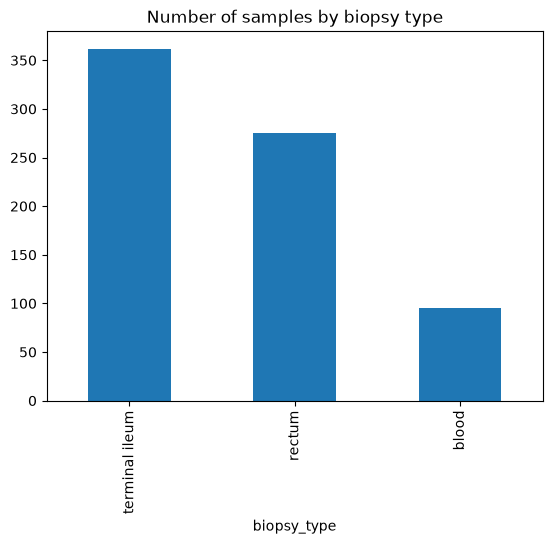

In [14]:
samples_df['biopsy_type'].value_counts().plot(kind='bar', title='Number of samples by biopsy type')

In [17]:
individuals_df.head()

,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
0,IBDverse-1-3A5C2FF82FA8A4,CD,40,male,inflamed
1,IBDverse-1-0DD5B680D0BFFB,CD,60,male,inflamed
2,IBDverse-1-B257F708E64F29,CD,30,female,inflamed
3,IBDverse-1-8D29C5BD7C12C7,CD,40,female,inflamed
4,IBDverse-1-B45A577AF0E969,CD,30,female,inflamed


In [19]:
individuals_df.shape

(421, 5)

In [18]:
individuals_df['disease_status'].value_counts()

disease_status
Healthy    296
CD         125
Name: count, dtype: int64

<Axes: title={'center': 'Number of individuals by age group'}, xlabel='age_binned_10'>

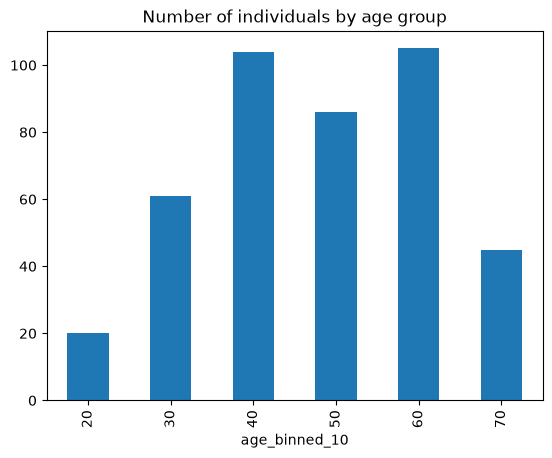

In [23]:
individuals_df['age_binned_10'].value_counts().sort_index().plot(kind='bar', title='Number of individuals by age group')

In [24]:
individuals_df['sex'].value_counts()

sex
female    220
male      201
Name: count, dtype: int64

In [56]:
individuals_df.groupby('disease_status')['ti_ses_inflamed'].value_counts()

disease_status  ti_ses_inflamed
CD              inflamed            72
                uninflamed          53
Healthy         uninflamed         296
Name: count, dtype: int64

In [55]:
individuals_df[individuals_df['disease_status'] == 'CD'].groupby('ti_ses_inflamed')['sex'].value_counts()

ti_ses_inflamed  sex   
inflamed         male      36
                 female    36
uninflamed       female    32
                 male      21
Name: count, dtype: int64

In [29]:
individuals_df.groupby('disease_status')['sex'].value_counts()

disease_status  sex   
CD              female     68
                male       57
Healthy         female    152
                male      144
Name: count, dtype: int64

In [39]:
individuals_df.groupby('disease_status')['age_binned_10'].agg(['count', 'mean', 'min', 'max', 'median'])


,count,mean,min,max,median
disease_status,,,,,
CD,125,41.760000,20,70,40.0
Healthy,296,50.405405,20,70,50.0


In [40]:
samples_to_individuals_df.head()

,individual_id,sanger_sample_id
0,IBDverse-1-3A5C2FF82FA8A4,5892STDY10205765
1,IBDverse-1-0DD5B680D0BFFB,5892STDY10315937
2,IBDverse-1-B257F708E64F29,5892STDY10315938
3,IBDverse-1-8D29C5BD7C12C7,5892STDY10653007
4,IBDverse-1-B45A577AF0E969,5892STDY10653009


In [47]:
temp_mapping = pd.merge(samples_df, samples_to_individuals_df, on='sanger_sample_id', how='left')
mapping_df = pd.merge(temp_mapping, individuals_df, on='individual_id', how='left')

In [49]:
mapping_df.shape

(732, 14)

In [50]:
mapping_df.head()

,sanger_sample_id,biopsy_type,bead_version,bead_lot,chip_version,chip_lot,enzyme_lot_BLP,gem_lot,f2_f1_ratio,individual_id,disease_status,age_binned_10,sex,ti_ses_inflamed
0,5892STDY10205765,terminal ileum,V3.1,NaN,chip-g,lot_160047,SLCB6672,lot_155287,04:01:00,IBDverse-1-3A5C2FF82FA8A4,CD,40,male,inflamed
1,5892STDY10315937,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00,IBDverse-1-0DD5B680D0BFFB,CD,60,male,inflamed
2,5892STDY10315938,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,01:00:00,IBDverse-1-B257F708E64F29,CD,30,female,inflamed
3,5892STDY10653007,terminal ileum,V3.1,lot_160848,chip-g,lot_160047,SLCD4967,lot_160900,04:01:00,IBDverse-1-8D29C5BD7C12C7,CD,40,female,inflamed
4,5892STDY10653009,terminal ileum,V3.1,lot_160848,chip-g,lot_160673,SLCD4967,lot_160851,01:00:00,IBDverse-1-B45A577AF0E969,CD,30,female,inflamed


In [57]:
mapping_df.groupby('biopsy_type')['disease_status'].value_counts()

biopsy_type     disease_status
blood           CD                 95
rectum          Healthy           275
terminal ileum  Healthy           243
                CD                119
Name: count, dtype: int64

In [67]:
individuals_df.groupby(['disease_status', 'ti_ses_inflamed'])['age_binned_10'].describe()

count       mean        std   min   25%   50%  \
disease_status ti_ses_inflamed                                                  
CD             inflamed          72.0  39.722222  10.066290  20.0  30.0  40.0   
               uninflamed        53.0  44.528302  13.525764  20.0  30.0  40.0   
Healthy        uninflamed       296.0  50.405405  13.697872  20.0  40.0  50.0   

                                 75%   max  
disease_status ti_ses_inflamed              
CD             inflamed         40.0  60.0  
               uninflamed       50.0  70.0  
Healthy        uninflamed       60.0  70.0

In [66]:
mapping_df.groupby(['disease_status', 'ti_ses_inflamed'])['age_binned_10'].describe()

count       mean        std   min   25%   50%  \
disease_status ti_ses_inflamed                                                  
CD             inflamed         119.0  40.252101   9.954318  20.0  30.0  40.0   
               uninflamed        95.0  44.526316  13.508738  20.0  30.0  40.0   
Healthy        uninflamed       518.0  50.038610  13.711537  20.0  40.0  50.0   

                                 75%   max  
disease_status ti_ses_inflamed              
CD             inflamed         45.0  60.0  
               uninflamed       55.0  70.0  
Healthy        uninflamed       60.0  70.0

<Axes: title={'center': 'Age distribution by disease status and inflammation status'}, xlabel='disease_status,ti_ses_inflamed,age_binned_10'>

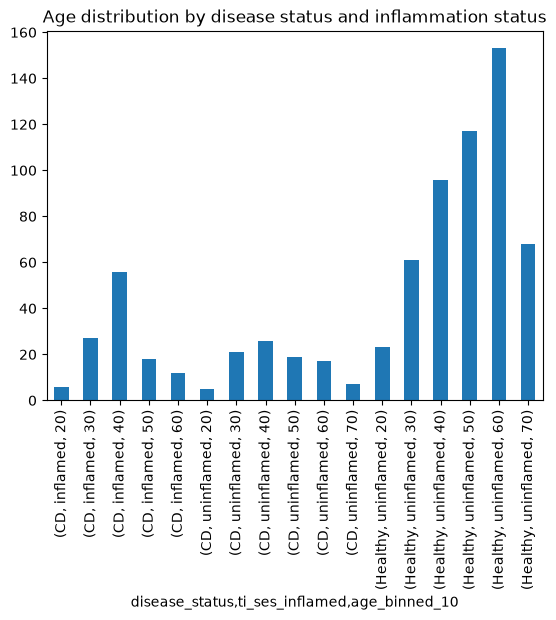

In [65]:
mapping_df.groupby(['disease_status', 'ti_ses_inflamed'])['age_binned_10'].value_counts().sort_index().plot(kind='bar', title='Age distribution by disease status and inflammation status')